# ASISTENTE VACACIONAL CON RAG Y TOOLS

## Imports, definición de modelos, creación de cliente

In [1]:
import os, getpass
from dotenv import load_dotenv
from google import genai
from pathlib import Path
import pymupdf
from langchain_text_splitters import RecursiveCharacterTextSplitter
import numpy as np
import faiss
from google.genai import types
from typing import Any
import requests
import pandas as pd
import matplotlib.pyplot as plt


# cargamos variables desde .env 
dotenv_loaded = load_dotenv()

# solicita claves si no están definidas
if not os.getenv("GOOGLE_API_KEY"):
    os.environ["GOOGLE_API_KEY"] = getpass.getpass("Introduce la API de Google: ")

# error si después de todo no tenemos API KEYs
if not os.getenv("GOOGLE_API_KEY"):
    raise RuntimeError("Claves no encontradas.")

print("Claves cargadas.")

Matplotlib is building the font cache; this may take a moment.


Claves cargadas.


Cargamos la API key de Google en `GOOGLE_API_KEY`

In [2]:
GENERATION_MODEL = os.getenv("GOOGLE_GENERATION_MODEL", "gemini-3.5-flash-lite")
EMBEDDING_MODEL = os.getenv("GOOGLE_EMBEDDING_MODEL", "gemini-embedding-001")

print("Modelo de generación: ", GENERATION_MODEL)
print("Modelo de embeddings: ", EMBEDDING_MODEL)

Modelo de generación:  gemini-3.5-flash-lite
Modelo de embeddings:  gemini-embedding-001


In [ ]:
# creamos cliente para comunicarnos con Google-genai
client = genai.Client()

## Carga PDF RAG

In [ ]:
# ruta del pdf para el RAG
PDF_PATH = Path("data/TENERIFE.pdf")

pages = []

# leemos cada página del pdf
with pymupdf.open(PDF_PATH) as doc:
    # page representa el contenido de la propia hoja, i representa el número de página
    for i, page in enumerate(doc, start=1):
        # añadimos número de página y contenido
        pages.append(
            {
                "page": i,
                "content": page.get_text()
            }
        )

print("Número de páginas cargadas:", len(pages))
print("Primeros caracteres:\n")
print(pages[0]["content"][:300])


Número de páginas cargadas: 25
Primeros caracteres:

TENERIFE – LUGARES DE INTERÉS 
SITIOS QUE VER 
 
ZONA NORTE 
 
• Santa Cruz de Tenerife: 
Santa Cruz de Tenerife es la capital de la isla. Quizás la ruta a seguir si vais a Santa 
Cruz sería: 
- 
Aparcar en el aparcamiento del Parque Marítimo (ubicación). 
- 
Caminar por la Avenida Marítima hasta Pl


## Chunking

In [ ]:
# separador de textos
splitter = RecursiveCharacterTextSplitter(
    chunk_size=700, # tamaño máximo de los chunks
    chunk_overlap=100, # solapamiento entre chunks
    separators=["\n\n", "\n", ". ", ", ", " ", ""] # separadores por orden de prioridad
)

chunks = []

# recorremos páginas
for page in pages:
    # dividimos cada página en chunks
    page_chunks = splitter.split_text(page["content"])

    # añadimos chunk_id, número de página y chunk 
    for chunk in page_chunks:
        chunks.append(
            {
                "chunk_id": len(chunks),
                "page": page["page"],
                "text": chunk
            }
        )

print(f"Se han obtenido {len(chunks)} chunks.")
print()
print("Chunk 1:")
print(chunks[0])

Se han obtenido 37 chunks.

Chunk 1:
{'chunk_id': 0, 'page': 1, 'text': 'TENERIFE – LUGARES DE INTERÉS \nSITIOS QUE VER \n \nZONA NORTE \n \n• Santa Cruz de Tenerife: \nSanta Cruz de Tenerife es la capital de la isla. Quizás la ruta a seguir si vais a Santa \nCruz sería: \n- \nAparcar en el aparcamiento del Parque Marítimo (ubicación). \n- \nCaminar por la Avenida Marítima hasta Plaza de España (ubicación). \n- \nPor el camino de la Avenida Marítima, ver el auditorio de Tenerife (ubicación). \n- \nUna vez llegados a Plaza España, callejear un poco (subir la Calle Castillo \ndirección Plaza Weyler - ubicación –; ir hacia el Parque García Sanabria - \nubicación -; y bajar de nuevo hacia Plaza de España pasando por la Plaza del \nPríncipe - ubicación). \n-'}


Para el proceso de chunking se utliza la función recursiva de langchain `RecursiveCharacterTextSplitter`. Se ha elegido porque se ha considerado la opción más óptima de hacer el chunking. Sigue una jerarquía de separadores para dividir los chunks, ordenados de mayor a menor importancia, estipulada en el parámetro `separators`.

## Embedding 

In [ ]:
def embed_texts(texts: list[str], task_type: str) -> np.array:
    """Embedding del texto, devuelve matriz numpy con embedding. 

    Args:
        texts: texto que sometemos a embedding.
        task_type: RETRIEVAL_DOCUMENT para documentos RETRIEVAL_QUERY para consultas

    Returns:
        lista de texto después de embedding
    """
    # llamamos al modelo de embedding utilizando el cliente
    response = client.models.embed_content(
        model=EMBEDDING_MODEL,
        contents=texts,
        config=types.EmbedContentConfig(
            task_type=task_type
        )
    )
    # guardamos vectores de embeddings 
    vectors = [item.values for item in response.embeddings]
    return np.array(vectors, dtype=np.float32)


In [7]:
# guardamos solo texto de todos los chunks
chunk_texts = [chunk["text"] for chunk in chunks]

# Llamamos a función de embedding
chunk_embeddings = embed_texts(
    texts=chunk_texts,
    task_type="RETRIEVAL_DOCUMENT"
)


# normalizamos vectores para similitud coseno
faiss.normalize_L2(chunk_embeddings)

# obtenemos dimensiones de ebeddings
dimension = chunk_embeddings.shape[1]

# creamos indice FAISS
index = faiss.IndexFlatIP(dimension)

# añadimos embeddings
index.add(chunk_embeddings)

print(f"Vectores almacenados: {index.ntotal}")


Vectores almacenados: 37


`faiss.normalize_L2`: convierte los embeddings en vectores de longitud 1.

`IndexFlatIP`: crea un índice que utiliza el producto interno y realiza una búsqueda exacta.

`index.add`: incorpora los embeddings al índice.

## Recuperación del contexto

In [ ]:
def search_internal_docs(query: str, index, k: int = 4) -> list[dict[str, Any]]:
    """Recupera k chunks más relevantes
    
    Args:
        query: consulta
        index: índice para búsqueda con FAISS
        k: número de chunks que queremos recuperar

    Returns:
        chunks devueltos con ranking y score de similitud
    
    """
    # embedding de la query
    query_embedding = embed_texts(
        texts=[query],
        task_type="RETRIEVAL_QUERY"
    )

    # normalizamos 
    faiss.normalize_L2(query_embedding)

    # buscamos k vectores similares 
    scores, indexes = index.search(
        x=query_embedding,
        k=min(k, index.ntotal)
    )

    results = []
    # index.search() devuelve dos matrices, puede recibir más de una pregunta en la misma llamada, en [0] está la primera pregunta
    for rank, (score, idx) in enumerate (zip(scores[0], indexes[0]), start=1):
        chunk = chunks[int(idx)]
        results.append(
            {
                "rank": rank,
                "score": float(score),
                "chunk_id": chunk["chunk_id"],
                "page": chunk["page"],
                "text": chunk["text"]
            }
        )

    return results

def print_recovered_chunks(results) -> None:
    """Printea los chunks devueltos"""
    for result in results:
        print("Chunk rank: ", result["rank"])
        print("Score: ", result["score"])
        print("chunk_id: ", result["chunk_id"])
        print("Page: ", result["page"])
        print("Content:")
        print(result["text"])
        print()
        print()

In [9]:
# prueba de función de recuperación de contexto 
results_1 = search_internal_docs(
    query="¿Qué miradores se recomiendan para visitar el Parque Rural de Anaga?",
    index=index,
    k=3
)

print_recovered_chunks(results_1)

Chunk rank:  1
Score:  0.7613589763641357
chunk_id:  6
Page:  5
Content:
la Playa de Benijo (imprescindible que esté soleado para poder ver el atardecer en 
esta playa, ya que es espectacular). 
 
Algunos de los miradores que os recomiendo en la ruta por Anaga: 
o Mirador de La Jardina (diría que es mi mirador favorito) [ubicación]


Chunk rank:  2
Score:  0.7611202001571655
chunk_id:  5
Page:  5
Content:
• Parque rural de Anaga 
Es un espacio natural protegido, declarado Reserva de la Biosfera y que cuenta con la 
mayor cantidad de endemismos de Europa. 
Tiene bastantes miradores chulísimos y rutas que podéis hacer si os mola este tipo 
de planes y si teníais pensado alguna caminata (véase Las Mejores Rutas en Parque 
Rural de Anaga). 
Visitar esta zona de la isla es un must y lo suyo sería que aprovecharais un día, os 
levantarais temprano, visitarais La Laguna y desayunarais por allí y ya luego rollo 
11:00-12:00 tiréis hacia Anaga, parando en algunos de los miradores y llegando has

In [10]:
results_2 = search_internal_docs(
    query="¿Dónde puedo disfrutar de la gastronomía tradicional canaria en un restaurante auténtico?",
    index=index,
    k=3
)

print_recovered_chunks(results_2)

Chunk rank:  1
Score:  0.6999064087867737
chunk_id:  34
Page:  24
Content:
[Tripadvisor] (os podría recomendar más guachinches, pero diría que 
este es mi favorito) 
 
Nota: los Guachinches son típicos en la zona norte de Tenerife. 
Actualmente existen muchos restaurantes que se llaman Guachinches 
pero no son los originales, ya que tienen una carta mucho más amplia 
y, por así decirlo, es más como un restaurante común (aunque la 
comida también estará increíble), pero la experiencia de Guachinche 
Guachinche es un sitio como el que he indicado.  
 
▪ Pizzería Gioconda (zona de La Orotava [ubicación]) [Tripadvisor] 
▪ El Palestra (zona de La Orotava [ubicación]. Este es el típico sitio que 
ha estado toda la vida en La Orotava y que te pides a domicilio cuando


Chunk rank:  2
Score:  0.694322943687439
chunk_id:  33
Page:  24
Content:
▪ Guachinche El Cubano (zona de Santa Úrsula [ubicación]. Para llegar 
atravesaréis una especie de camino de tierra, meteos sin miedo. Si 
vais a Tenerif

In [ ]:
def format_results_with_sources(results) -> str:
    """formatea contexto guardando fuente
    
    Args:
        results: chunks
        
    Returns:
        chunks formateados a string
    """
    blocks = []
    for i, res in enumerate(results, start=1):
        score = res.get("score")
        page = res.get("page", "?")
        chunk_id = res.get("chunk_id", "?")
        text = res.get("text")
        blocks.append(
            f"Score {score:.3f} Página {page}, chunk {chunk_id}\n{text}"
        )
    return "\n\n".join(blocks)
    

## Log para llamadas a herramientas 

In [ ]:
tool_logs = []

def register_tool_call(name, arguments, result, error = None) -> None:
    """Registro de las llamadas a herramientas function_call
    
    Args:
        name: nombre de la herramienta llamada
        arguments: argumentos con los que se le ha llamado
        result: lo que ha devuelto la herramienta
        error: error (si se ha dado)
    """
    tool_logs.append({
        "tool": name,
        "arguments": arguments,
        "success": error is None,
        "result": result,
        "error": str(error) if error else None
    })

## RAG como herramienta 

In [ ]:
def search_internal_docs_tool(query: str, k: int = 3) -> str:
    """Busca información turística en la guía de Tenerife y devuelve los k fragmentos más relevantes con sus páginas.
    
    Args:
        query: consulta
        k: número de chunks que queremos recuperar

    Returns:
        información solicitada en forma de chunks formateada string
    """

    results = search_internal_docs(query, index, k)
    return format_results_with_sources(results)

# declaración de la herramienta para búsqueda de información en RAG
search_internal_docs_tool_schema = types.FunctionDeclaration(
    name="search_internal_docs_tool",
    description="Search the Tenerife tourist guide and retrieve the most relevant text chunks, including their sources and page numbers.",
    parameters_json_schema={
        "type": "object",
        "properties": {
            "query": {
                "type": "string",
                "description": "Search query about tourist information in Tenerife."
            },
            "k": {
                "type": "integer",
                "description": "Number of relevant text chunks to retrieve. Default is 3.",
                "minimum": 1,
                "maximum": 8
            }
        },
        "required": ["query"],
        "additionalProperties": False
    }
)

## Herramienta tiempo en Tenerife

In [ ]:
def get_weather_tool(date: str) -> dict[str, Any]:
    """Obtiene el tiempo para una fecha (aaaa-mm-dd) en Santa Cruz de Tenerife
    
    Args:
        date: fecha de la que se quiere la previsión meteorológica (aaaa-mm-dd)
        
    Returns:
        información metorológica: día, temperatua máxima y mínima, precipitación y estado del cielo"""
    
    # API de Open-Meteo
    url = "https://api.open-meteo.com/v1/forecast"
    # datos de consulta con coordenadas de tenerife
    params = {
        "latitude": 28.4636,
        "longitude": -16.2518,
        "start_date": date,
        "end_date": date,
        "daily": [
            "temperature_2m_max",
            "temperature_2m_min",
            "precipitation_sum",
            "weather_code"
        ],
        "timezone": "Atlantic/Canary"
    }

    # petición a la API con parámetros definidos
    response = requests.get(url, params)
    response.raise_for_status()
    data = response.json()

    # lista para decodificación de estado del cielo
    weather_codes = {
        0: "Clear sky",
        1: "Mainly clear",
        2: "Partly cloudy",
        3: "Overcast",
        45: "Fog",
        61: "Light rain",
        63: "Moderate rain",
        65: "Heavy rain",
        95: "Thunderstorm"
    }

    code = data["daily"]["weather_code"][0]
    weather = weather_codes.get(code, "unknown")
        

    result = {
        "time": data["daily"]["time"][0],
        "temperature_max": data["daily"]["temperature_2m_max"][0],
        "temperature_min": data["daily"]["temperature_2m_min"][0],
        "precipitation_sum": data["daily"]["precipitation_sum"][0],
        "weather": weather
    }

    return result

# declaración de la herramienta para saber el tiempo
get_weather_tool_schema = types.FunctionDeclaration(
    name="get_weather_tool",
    description="Get the weather forecast for a specific date.",
    parameters_json_schema={
        "type": "object",
        "properties": {
            "date": {
                "type": "string",
                "description": "Date for the weather forecast in YYYY-MM-DD format.",
                "format": "date"
            }
        },
        "required": ["date"],
        "additionalProperties": False
    }
)

## Instrucciones para los distintos modelos

In [16]:
MAIN_LLM_SYSTEM_INSTRUCTIONS = """
    Eres un asistente turístico especializado en Tenerife.
    Tu objetivo es ayudar al usuario a organizar su viaje, recomendar lugares
    de interés y resolver dudas turísticas de manera clara, útil, breve y cercana.
    
    USO DE HERRAMIENTAS:
    - Dispones de dos herramientas, una para consultar una guía turística de Tenerife
      y otra para obtener predicciones meteorológicas.
    - Utiliza search_internal_docs_tool cuando el usuario pregunte por playas,
      monumentos, restaurantes, actividades, rutas o recomendaciones turísticas.
    - Basa tus recomendaciones en la información recuperada de la guía.
    - Utiliza get_weather_tool cuando el usuario pregunte por el tiempo , las
      temperaturas, la lluvia o las condiciones meteorológicas de una fecha 
      concreta.
    - Pídele al usuario que te dé la fecha/fechas exactas sobre las que quiere la
      previsión meteorológica antes de llamar a la herramienta.
    - Si una recomendación depende del tiempo, utiliza ambas herramientas
      para combinar la información turística con la meteorológica.
    - No inventes datos meteorológicos ni afirmes haber consultado una
      herramienta si no la has ejecutado.
    
    GESTIÓN DE INFORMACIÓN:
    - Prioriza la información obtenida de las herramientas.
    - Cita las páginas de la guía turística utilizadas en tus respuestas.
    - Si la guía no contiene la información solicitada, indícalo claramente.
    - Si una herramienta devuelve un error, explícalo sin inventar resultados.
    - No presentes como actuales datos que puedan haber cambiado, como
      horarios, precios, restricciones de acceso o disponibilidad.
    
    CONTEXTO CONVERSACIONAL:
    - Ten en cuenta el historial proporcionado para mantener la coherencia.
    - Recuerda las preferencias, fechas y lugares mencionados anteriormente.
    - Interpreta preguntas de seguimiento teniendo en cuenta la conversación.
    - No vuelvas a consultar herramientas innecesariamente si la información
      anterior sigue siendo suficiente y válida.
    
    ESTILO DE RESPUESTA:
    - Responde siempre en español.
    - Utiliza un lenguaje natural, cercano y fácil de entender.
    - Ofrece respuestas concretas, evitando explicaciones innecesarias.
    - Organiza las recomendaciones de forma clara cuando sea útil.
    - Si no dispones de información suficiente, reconócelo.
"""

SUMMARIZE_LLM_SYSTEM_INSTRUCTIONS = """
    Eres un asistente especializado en resumir historiales de conversación.
    Tu tarea es condensar la conversación proporcionada para que otro
    asistente, especializado en ser una guía turística, pueda continuarla sin perder 
    información relevante.
    Instrucciones:
    - Conserva las preferencias, necesidades y restricciones del usuario.
    - Conserva los lugares turísticos, fechas y actividades mencionados.
    - Conserva las recomendaciones realizadas y las decisiones tomadas.
    - Mantén los datos necesarios para comprender futuras preguntas.
    - Elimina saludos, repeticiones e información irrelevante.
    - No inventes información ni añadas conocimientos externos.
    - No incluyas información que no esté presente en el historial.
    - Redacta un resumen breve, claro y estructurado.                    
    - Devuelve únicamente el texto del resumen, sin explicaciones adicionales.
"""

## Parámetros para el modelo

In [ ]:
# añade creatividad
TEMPERATURE = 0.3
# número máximo de tokens de salida
MAX_OUTPUT_TOKENS = 1000

## Control de historial

In [ ]:
# límite de tokens para la conversación
MAX_TOKENS = 5000    

def exceeds_token_limit(conversation: list[types.Content]) -> bool:
    """comprueba si se ha sobrepasado el límite de tokens
    
    Args:
        conversation: contexto de la conversación

    Returns:
        True si se ha sobrepasado el límite
    """
    # contamos tokens de la variable conversation
    token_count = client.models.count_tokens(
        model=GENERATION_MODEL,
        contents=conversation
    )
    if token_count.total_tokens > MAX_TOKENS:
        return True
    else:
        return False

def conversational_context_control(conversation: list[types.Content], query: str = None) -> list[types.Content]:
    """Resume el historial si sobrepasa el límite de tokens
    
    Args:
        conversation: contexto de la conversación
        query: última consulta 
        
    Returns:
        contexto de la conversación sin sobrepasar límite 
    """
    if exceeds_token_limit(conversation):
        # llamada a modelo para que resuma el historial
        summary = client.models.generate_content(
            model=GENERATION_MODEL,
            contents=conversation[:-1], # excluimos última pregunta del user
            config=types.GenerateContentConfig(
                system_instruction=SUMMARIZE_LLM_SYSTEM_INSTRUCTIONS
            )
        )
        conversation: list[types.Content] = [] 
        # añade resumen y última pregunta
        conversation.extend(
            [
                types.Content(
                    role = "user",
                    parts=[types.Part.from_text(text=f"Resumen de la conversación anterior:\n{summary.text}")]
                ),
                types.Content(
                        role = "user",
                        parts=[types.Part.from_text(text=query)]
                )
            ]
        )
    return conversation

    

In [ ]:
# registro de las herramientas, nombre + Callable 
registry = {
    "search_internal_docs_tool": search_internal_docs_tool,
    "get_weather_tool": get_weather_tool,
}

def execute_tool_call(call: Any) -> dict[str, Any]:
    """Ejecuta una llamada a una herramienta
    
    Args:
        call: info sobre la llamada
        
    Returns:
        resultado de la llamada
    """

    # nombre de la herramienta que se quiere llamar
    name = call.name
    try:
        # argumentos para llamar a la herramienta
        arguments = dict(call.args or {})
        if name not in registry:
            raise ValueError(f"Herramienta no registrada: {name}")
        # Callable de la herramienta solicitada
        tool = registry[name]
        # llamada a la herramienta con los argumentos
        output = tool(**arguments)
        # registro de la llamada
        register_tool_call(
            name=name,
            arguments=arguments,
            result=output, 
            error=None
        )
    except Exception  as exc:
        arguments = locals().get("arguments", {})
        output = {"error_type": type(exc).__name__, "message": str(exc)}
        register_tool_call(
            name=name,
            arguments=arguments,
            result=None, 
            error=output
        )
    return {"result": output}


def run_llm_with_tools(user_input: str, conversation: list[types.Content], max_tool_rounds: int = 5) -> dict[str, Any]:
    """Invoca al modelo con herramientas; devuelve respuesta generada, herramientas utilizadas y contexto
    
    Args:
        user_input: consulta del usuario
        conversation: contexto de la conversación 
        max_tool_rounds: número máximo de llamadas a herramientas
        
    Returns:
        respuesta del modelo y contexto de conversación
    """
    
    # control del historial y tokens
    conversation.append(
        types.Content(
            role="user",
            parts=[types.Part.from_text(text=user_input)]
        )
    )
    conversation_and_query = conversational_context_control(conversation, user_input)
    
    for round_index in range(max_tool_rounds + 1):
        
        # llamada al cliente con tools y ejecución automática de las mismas
        stream = client.models.generate_content_stream(
            model=GENERATION_MODEL,
            contents=conversation_and_query,
            config=types.GenerateContentConfig(
                system_instruction=MAIN_LLM_SYSTEM_INSTRUCTIONS,
                temperature = TEMPERATURE,
                max_output_tokens = MAX_OUTPUT_TOKENS,
                tools=[
                    types.Tool(
                        function_declarations=[
                            search_internal_docs_tool_schema,
                            get_weather_tool_schema
                        ]
                    )
                ],
                automatic_function_calling=types.AutomaticFunctionCallingConfig(
                    disable=True
                )
            )
        )

        response = ""
        function_calls = []
        model_parts = []
        
        # Recorremos los fragmentos del streaming
        for chunk in stream:
            if not chunk.candidates:
                continue
                
            content = chunk.candidates[0].content

            if content is None:
                continue

            for part in content.parts or []:
                # Conservamos las partes originales para el historial
                model_parts.append(part)
                # Texto generado
                if part.text and not part.thought:
                    print(part.text, end="", flush=True)
                    response += part.text
                # Llamadas a herramientas
                if part.function_call:
                    function_calls.append(part.function_call)

        print()

        # Guardamos el mensaje del modelo
        if model_parts:
            conversation_and_query.append(
                types.Content(
                    role="model",
                    parts=model_parts
                )
            )

        # si no solicita herramientas terminamos
        if not function_calls:
            conversation_and_query.append(
                types.Content(
                    role="model",
                    parts=[types.Part.from_text(text=response)]
                )
            )
            return {
                "text": response,
                "conversation": conversation_and_query
            }

        tool_parts = []
        for call in function_calls:
            payload = execute_tool_call(call)
            
            # Convertimos el resultado al formato de Gemini
            tool_parts.append(
                types.Part.from_function_response(
                    name=call.name,
                    response=payload
                )
            )
        # añadimos la respuesta
        conversation_and_query.append(
            types.Content(
                role="user",
                parts=tool_parts
            )
        )
    
    raise RuntimeError(f"Se alcanzó el límite de {max_tool_rounds} rondas de herramientas.")

    

In [64]:
# "main"
conversation: list[types.Content] = []

while True:
    query = input("Pregunta a gemini, 'exit' para salir")
    if query.lower() in ("exit", "salir"):
        break

    print("-"*80)
    print("RESPUESTA DEL MODELO")
    print()
    response = run_llm_with_tools(
        user_input = query,
        conversation = conversation
    )
    print("-"*80)
    print()
    conversation = response["conversation"]
    

Pregunta a gemini, 'exit' para salir dime el tiempo de mañana


--------------------------------------------------------------------------------
RESPUESTA DEL MODELO


¡Vaya, ha ocurrido un pequeño error al consultar el servicio meteorológico! ¿Podrías indicarme la fecha exacta (año, mes y día) para la que quieres que compruebe el tiempo?
--------------------------------------------------------------------------------



Pregunta a gemini, 'exit' para salir 20-10-2026


--------------------------------------------------------------------------------
RESPUESTA DEL MODELO


Para el **20 de octubre de 2026** se espera un día nublado (*overcast*), con una temperatura máxima de unos 24,9 °C, una mínima de 20,5 °C y sin previsión de lluvias. ¡Un clima bastante agradable para pasear por la isla! 

¿Te gustaría que te recomiende algún lugar o actividad para ese día?
--------------------------------------------------------------------------------



Pregunta a gemini, 'exit' para salir si, recomiendame algo para mañana


--------------------------------------------------------------------------------
RESPUESTA DEL MODELO



Para mañana, teniendo en cuenta que el día estará nublado pero agradable (sin previsión de lluvia), es una ocasión perfecta para **subir al Parque Nacional del Teide** (Páginas 15-16). 

Al haber nubes por la zona norte, podrás disfrutar de un **espectacular mar de nubes** durante el ascenso. Aquí tienes una ruta recomendada:

* **Subida por la carretera TF-24 (La Esperanza):** Te sugiero empezar desde La Laguna y parar en el **Mirador de La Tarta** (para ver las curiosas formaciones de colores en la roca) y en el **Mirador de Chipeque** para contemplar el mar de nubes (Página 15).
* **Las Cañadas del Teide:** Llega hasta el Parador de las Cañadas y acércate al **mirador de La Ruleta** para disfrutar de las vistas más famosas de la zona (Página 15).
* **Opciones extra:** Puedes visitar el Centro de Visitantes de El Portillo (que es gratuito) o subir en el teleférico si te apetece ll

Pregunta a gemini, 'exit' para salir exit


In [20]:
for x in tool_logs:
    print(x)
    print()
    print()

## Evaluación del RAG

In [ ]:
rag_test_questions = [
    "¿Qué miradores se recomiendan para visitar en Tenerife?",
    "¿Dónde puedo disfrutar de la gastronomía tradicional canaria?",
    "¿Qué lugares puedo visitar en el Parque Rural de Anaga?",
    "¿Qué playas son recomendables en Tenerife?",
    "¿Qué actividades puedo realizar en el Teide?",
]

rag_results = []

for question in rag_test_questions:

    results = search_internal_docs(
        query=question,
        index=index,
        k=3
    )

    rag_results.append({
        "question": question,
        "top_1_score": results[0]["score"],
        "mean_score": sum(r["score"] for r in results) / len(results),
        "pages": [r["page"] for r in results],
        "chunks": [r["chunk_id"] for r in results]
    })

df_rag = pd.DataFrame(rag_results)
display(df_rag)

,question,top_1_score,mean_score,pages,chunks
0,¿Qué miradores se recomiendan para visitar en ...,0.746397,0.739772,"[15, 5, 15]","[20, 6, 21]"
1,¿Dónde puedo disfrutar de la gastronomía tradi...,0.699089,0.698596,"[24, 4, 24]","[33, 4, 32]"
2,¿Qué lugares puedo visitar en el Parque Rural ...,0.776500,0.750026,"[5, 5, 6]","[5, 6, 7]"
3,¿Qué playas son recomendables en Tenerife?,0.767073,0.751960,"[23, 11, 16]","[31, 12, 23]"
4,¿Qué actividades puedo realizar en el Teide?,0.729594,0.721718,"[15, 16, 15]","[20, 22, 21]"


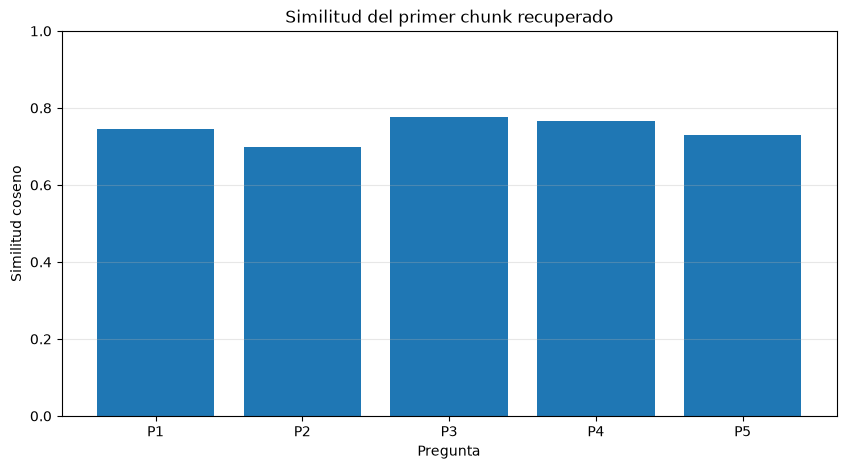

In [22]:
plt.figure(figsize=(10, 5))

plt.bar(
    range(len(df_rag)),
    df_rag["top_1_score"]
)

plt.xticks(
    range(len(df_rag)),
    [f"P{i+1}" for i in range(len(df_rag))]
)

plt.xlabel("Pregunta")
plt.ylabel("Similitud coseno")
plt.title("Similitud del primer chunk recuperado")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.show()

## Evaluación del function calling

In [ ]:
EVAL_CASES = [
    {
        "name": "informacion_turistica",
        "input": "¿Qué lugares puedo visitar en el Parque Rural de Anaga?",
        "expected_tools": {"search_internal_docs_tool"},
    },
    {
        "name": "gastronomia",
        "input": "¿Qué platos típicos puedo probar en Tenerife?",
        "expected_tools": {"search_internal_docs_tool"},
    },
    {
        "name": "prevision_meteorologica",
        "input": "¿Qué tiempo hará en Tenerife el 20 de octubre de 2026?",
        "expected_tools": {"get_weather_tool"},
    },
    {
        "name": "turismo_y_meteorologia",
        "input": (
            "¿Qué actividades turísticas de la guía me recomiendas "
            "para el 20 de octubre de 2026 teniendo en cuenta "
            "la previsión meteorológica?"
        ),
        "expected_tools": {
            "search_internal_docs_tool",
            "get_weather_tool"
        },
    },
    {
        "name": "pregunta_general",
        "input": "Explícame brevemente qué es el turismo sostenible.",
        "expected_tools": set(),
    },
    {
        "name": "saludo",
        "input": "Hola, buenos días.",
        "expected_tools": set(),
    },
    {
    "name": "fecha_pasada",
    "input": "¿Qué tiempo hizo en Tenerife el 15 de enero de 2020?",
    "expected_tools": {"get_weather_tool"},
},
{
    "name": "informacion_fuera_rag",
    "input": (
        "Según la guía turística, ¿cuál es el número de teléfono "
        "personal del alcalde de Santa Cruz de Tenerife?"
    ),
    "expected_tools": {"search_internal_docs_tool"},
},
]

def evaluate_tool_selection(cases: list[dict[str, Any]]) -> pd.DataFrame:
    """Evalúa si Gemini selecciona las herramientas correctas para cada caso.
    
    Args:
        cases: lista de casos para la evaluación
        
    Returns:
        DataFrame con los resultados obtenidos frente a los esperados
    """

    rows = []

    for case in cases:

        # Guardamos la posición actual del log
        log_start = len(tool_logs)

        try:
            run_result = run_llm_with_tools(
                user_input=case["input"],
                conversation=[],  # Conversación independiente para cada prueba
                max_tool_rounds=4
            )

            # Obtenemos las herramientas utilizadas en esta prueba
            new_logs = tool_logs[log_start:]
            observed_tools = {log["tool"] for log in new_logs}

            output_preview = run_result["text"][:240]
            error = None

        except Exception as exc:
            new_logs = tool_logs[log_start:]
            observed_tools = {log["tool"] for log in new_logs}
            output_preview = ""
            error = f"{type(exc).__name__}: {exc}"

        rows.append(
            {
                "case": case["name"],
                "expected_tools": case["expected_tools"],
                "observed_tools": observed_tools,
                "tool_selection_ok": observed_tools == case["expected_tools"],
                "error": error,
                "output_preview": output_preview,
            }
        )

    return pd.DataFrame(rows)

In [27]:
eval_df = evaluate_tool_selection(EVAL_CASES)

display(eval_df)


¡Hola! El Parque Rural de Anaga es un espacio natural protegido y Reserva de la Biosfera imprescindible en Tenerife (Pág. 5). 

Te recomiendo organizar la visita pasando por los siguientes lugares destacados:

* **Mirador de La Jardina:** Uno de los miradores favoritos de la zona, ideal para hacer una parada y disfrutar de las vistas (Pág. 5 y 6).
* **Mirador Pico del Inglés:** Famoso por su frondoso pasillo de vegetación, perfecto para hacer la típica foto de recuerdo de Anaga (Pág. 6).
* **Playa de Benijo:** Un lugar imprescindible, especialmente al atardecer (si está soleado, las vistas son espectaculares) (Pág. 5 y 6).
* **Rutas de senderismo y miradores:** El parque cuenta con numerosos senderos y miradores ideales si te gusta caminar (Pág. 5).

**Consejo:** Lo ideal es aprovechar un día entero: levantarse temprano, visitar y desayunar en **La Laguna**, y hacia las 11:00-12:00 tirar hacia Anaga parando en los miradores hasta llegar a la Playa de Benijo (Pág. 5). 

Si vas a planif

,case,expected_tools,observed_tools,tool_selection_ok,error,output_preview
0,informacion_turistica,{search_internal_docs_tool},{search_internal_docs_tool},True,None,¡Hola! El Parque Rural de Anaga es un espacio ...
1,gastronomia,{search_internal_docs_tool},{search_internal_docs_tool},True,None,En Tenerife no puedes perderte la experiencia ...
2,prevision_meteorologica,{get_weather_tool},{get_weather_tool},True,None,El 20 de octubre de 2026 en Tenerife el tiempo...
3,turismo_y_meteorologia,"{get_weather_tool, search_internal_docs_tool}","{get_weather_tool, search_internal_docs_tool}",True,None,"Para el **20 de octubre de 2026**, la previsió..."
4,pregunta_general,{},{},True,None,El turismo sostenible es una forma de viajar q...
5,saludo,{},{},True,None,¡Buenos días! ¿Qué tal? ¿Estás planeando un vi...
6,fecha_pasada,{get_weather_tool},{get_weather_tool},True,None,"Lo siento, no he podido consultar el tiempo pa..."
7,informacion_fuera_rag,{search_internal_docs_tool},{search_internal_docs_tool},True,None,La guía turística no contiene esa información;...
